In [1]:
import pandas as pd

In [41]:
news = pd.read_table('data/ebnerd_demo_warm50/val/news.tsv', header=None, names=['news_id', 'category', 'subcategory', 'title', 'abstract', 'url'])

In [42]:
display(news)

,news_id,category,subcategory,title,abstract,url
0,3001353,140,0,Natascha var ikke den første,Sagen om den østriske Natascha og hendes bortf...,https://ekstrabladet.dk/krimi/article3001353.ece
1,3003065,414,433,Kun Star Wars tjente mere,Vatikanet har opfordret til at boykotte filmen...,https://ekstrabladet.dk/underholdning/filmogtv...
2,3012771,142,196,Morten Bruun fyret i SønderjyskE,Kemien mellem spillerne i Superligaklubben Søn...,https://ekstrabladet.dk/sport/fodbold/dansk_fo...
3,3023463,118,133,Luderne flytter på landet,Det frække erhverv rykker på landet. I den tyn...,https://ekstrabladet.dk/nyheder/samfund/articl...
4,3032577,565,0,Cybersex: Hvornår er man utro?,"De fleste af os mener, at et tungekys er utros...",https://ekstrabladet.dk/sex_og_samliv/article3...
...,...,...,...,...,...,...
20733,9803492,118,133,Vilde billeder: Vulkan i udbrud i ferieparadis,Det spyer med lava fra vulkanen Kilauea på Haw...,https://ekstrabladet.dk/nyheder/samfund/vilde-...
20734,9803505,142,327,Flyvende Antonsen knuser topspiller,Anders Antonsen har holdt pause fra badmintonb...,https://ekstrabladet.dk/sport/anden_sport/badm...
20735,9803525,414,425,"Dansk skuespiller: - Jeg nægtede, at jeg var syg","Mens hun lå søvnløs, lød kakofonien fra baggår...",https://ekstrabladet.dk/underholdning/dkkendte...
20736,9803560,118,0,Så slemt er det: 14.000 huse er oversvømmet,Et område på omkring 600 kvadratkilometer står...,https://ekstrabladet.dk/nyheder/saa-slemt-er-d...


In [43]:
# make a category2int dictionary and tsv file for category and subcategory, in 1 file
# please start with the category2int dictionary
# Get unique categories and subcategories
all_categories = pd.concat([news['category'], news['subcategory']]).unique()
all_categories = sorted([x for x in all_categories if pd.notna(x)])

# Create category2int dictionary starting from 1 (0 reserved for unknown/padding)
category2int = {cat: idx+1 for idx, cat in enumerate(all_categories)}

# Create dataframe and save to tsv
category2int_df = pd.DataFrame(category2int.items(), columns=['category', 'int'])
category2int_df.to_csv('data/ebnerd_demo_warm50/train/category2int.tsv', sep='\t', index=False, header=False)

print(f"Created mapping for {len(category2int)} unique categories")
print("\nFirst few category mappings:")
print(pd.DataFrame(list(category2int.items())[:10], columns=['Category', 'Integer']))


Created mapping for 109 unique categories

First few category mappings:
   Category  Integer
0         0        1
1         2        2
2        22        3
3        68        4
4        71        5
5        80        6
6        81        7
7       118        8
8       123        9
9       127       10


In [22]:
train_behaviors = pd.read_table('data/mind/train/behaviors.tsv', header=None, names=['impression_id', 'user', 'time', 'clicked_news', 'impressions'])
val_behaviors = pd.read_table('data/mind/val/behaviors.tsv', header=None, names=['impression_id', 'user', 'time', 'clicked_news', 'impressions'])

# concat train and val behaviors
behaviors = pd.concat([train_behaviors, val_behaviors])

# create a column clicked_news_length

In [30]:
# create a column clicked_news_length
behaviors['clicked_news_length'] = behaviors['clicked_news'].str.split().str.len()

# count the number of clicked_news_length greater than 50
warm = behaviors['clicked_news_length'] > 60

# count the number of clicked_news_length greater than 5 and less than 50
normal = (behaviors['clicked_news_length'] > 6) & (behaviors['clicked_news_length'] <= 50)

# count the number of clicked_news_length less than 5
cold = behaviors['clicked_news_length'] <= 5

print(warm.sum())
print(normal.sum())
print(cold.sum())









34584
136887
34476


In [5]:
display(train_behaviors)

,impression_id,user,time,clicked_news,impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...
2,3,U73700,11/14/2019 7:01:48 AM,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N50014-0 N23877-0 N35389-0 N49712-0 N16844-0 N...
3,4,U34670,11/11/2019 5:28:05 AM,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0
4,5,U8125,11/12/2019 4:11:21 PM,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...
...,...,...,...,...,...
156960,156961,U21593,11/14/2019 10:24:05 PM,N7432 N58559 N1954 N43353 N14343 N13008 N28833...,N2235-0 N22975-0 N64037-0 N47652-0 N11378-0 N4...
156961,156962,U10123,11/13/2019 6:57:04 AM,N9803 N104 N24462 N57318 N55743 N40526 N31726 ...,N3841-0 N61571-0 N58813-0 N28213-0 N4428-0 N25...
156962,156963,U75630,11/14/2019 10:58:13 AM,N29898 N59704 N4408 N9803 N53644 N26103 N812 N...,N55913-0 N62318-0 N53515-0 N10960-0 N9135-0 N5...
156963,156964,U44625,11/13/2019 2:57:02 PM,N4118 N47297 N3164 N43295 N6056 N38747 N42973 ...,N6219-0 N3663-0 N31147-0 N58363-0 N4107-0 N457...


In [47]:
mind_news = pd.read_table('data/mind/train/news.tsv', header=None, names=['news_id', 'category', 'subcategory', 'title', 'abstract', 'url', 'title_entities', 'abstract_entities'])
mind_val_news = pd.read_table('data/mind/val/news.tsv', header=None, names=['news_id', 'category', 'subcategory', 'title', 'abstract', 'url', 'title_entities', 'abstract_entities'])
# concat 
mind_news = pd.concat([mind_news, mind_val_news])

In [48]:
# count number of different category and subcategory please, please please
unique_categories = mind_news['category'].unique()
unique_subcategories = mind_news['subcategory'].unique()

print(f"Number of unique categories: {len(unique_categories)}")
print(f"Number of unique subcategories: {len(unique_subcategories)}")




Number of unique categories: 18
Number of unique subcategories: 270


In [35]:
# import matplotlib as plt please
import matplotlib.pyplot as plt

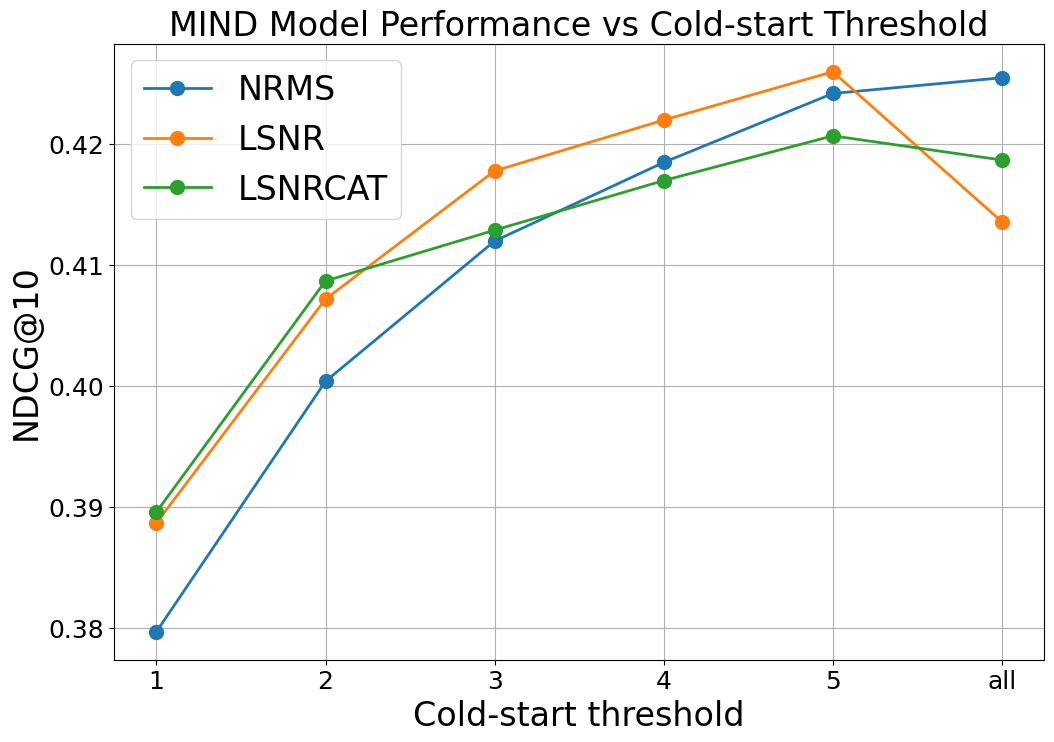

In [63]:
# x axis [1, 2, 3, 4, 5, 'all']
# randomly sample y axis from 0 to 1 for each x for each in ['nrms', 'naml', 'lstur', 'lsnr', 'lsnr_cat']
import numpy as np

x = [1, 2, 3, 4, 5, 'all']
models = ['NRMS', 'LSNR', 'LSNRCAT']

# Generate random data for each model
data = {}


data['NRMS'] = [0.3797, 0.4004, 0.4120, 0.4185, 0.4242, 0.4255]
data['LSNR'] = [0.3887, 0.4072, 0.4178, 0.4220, 0.4260, 0.4136]
data['LSNRCAT'] = [0.3896, 0.4087, 0.4129, 0.4170, 0.4207, 0.4187 ]

# Plot the data
plt.figure(figsize=(12, 8))
for model in models:
    plt.plot(x, data[model], marker='o', label=model, linewidth=2, markersize=10)

plt.xlabel('Cold-start threshold', fontsize=24)
plt.ylabel('NDCG@10', fontsize=24)
plt.title('MIND Model Performance vs Cold-start Threshold', fontsize=24)
plt.legend(fontsize=24)
plt.grid(True)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# save the plot
plt.savefig('mind_model_performance_vs_cold_start_threshold.png', dpi=300)

plt.show()


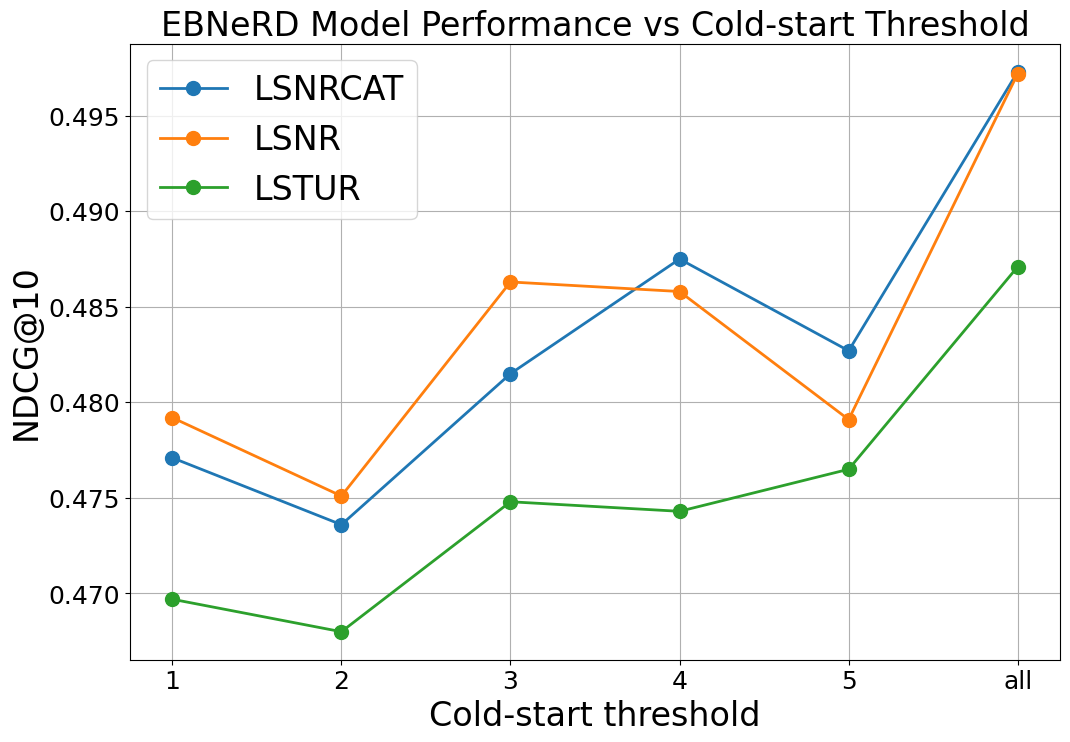

In [69]:
import numpy as np

x = [1, 2, 3, 4, 5, 'all']
models = ['LSTUR', 'LSNR', 'LSNRCAT']

# Generate random data for each model
data = {}

data['LSTUR'] = [0.4697, 0.4680, 0.4748, 0.4743, 0.4765, 0.4871]
data['LSNR'] = [0.4792, 0.4751, 0.4863, 0.4858, 0.4791, 0.4972]
data['LSNRCAT'] = [0.4771, 0.4736, 0.4815, 0.4875, 0.4827, 0.4973]


# Plot the data
plt.figure(figsize=(12, 8))
for model in models:
    plt.plot(x, data[model], marker='o', label=model, linewidth=2, markersize=10)

plt.xlabel('Cold-start threshold', fontsize=24)
plt.ylabel('NDCG@10', fontsize=24)
plt.title('EBNeRD Model Performance vs Cold-start Threshold', fontsize=24)
plt.legend(fontsize=24)
plt.grid(True)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# save the plot
plt.savefig('ebnerd_model_performance_vs_cold_start_threshold.png', dpi=300)

plt.show()

In [14]:
# load data/ebnerd_all/train/behaviors_parsed.tsv
behaviors = pd.read_table('data/ebnerd_all/train/behaviors_parsed.tsv')
val_behaviors = pd.read_table('data/ebnerd_all/val/behaviors_parsed_0.tsv', header=None, names=['impression_id', 'user', 'time', 'clicked_news', 'impressions', 'candidate_news', 'clicked'])
concat_behaviors = pd.concat([behaviors, val_behaviors])

In [20]:
import numpy as np
train_users = behaviors['user'].unique()
val_users = val_behaviors['user'].unique()
all_users = np.concatenate([train_users, val_users])
# create user2int.tsv file, counting from 1
user2int = pd.DataFrame({'user': all_users, 'int': range(1, len(all_users) + 1)})
user2int.to_csv('data/ebnerd_all/train/user2int.tsv', sep='\t', index=False, header=False)




In [21]:
# load data/ebnerd_all/train/user2int.tsv
user2int = pd.read_table('data/ebnerd_all/train/user2int.tsv', header=None, names=['user', 'int'])
display(user2int)

,user,int
0,139836,1
1,143471,2
2,151570,3
3,161621,4
4,163208,5
...,...,...
30477,169213,30478
30478,378776,30479
30479,990330,30480
30480,1090760,30481


In [ ]:
behaviors_parsed = pd.read_table('data/ebnerd_all/train/behaviors_parsed.tsv')

user2int = dict(pd.read_table(f'data/ebnerd_all/train/user2int.tsv').values.tolist())

behaviors_parsed['user'] = behaviors_parsed['user'].map(user2int)
behaviors_parsed['user'] = behaviors_parsed['user'].fillna(0)

In [26]:
# print number of unique values in behaviors_parsed['user']
print(len(behaviors_parsed['user'].unique()))


15140


In [30]:
behaviors_parsed = pd.read_table('data/ebnerd_all/val/behaviors_parsed_0.tsv', header=None,
                                       usecols=range(5),
                                       names=[
                                           'impression_id', 'user', 'time',
                                           'clicked_news', 'impressions'
                                       ])

behaviors_parsed['user'] = behaviors_parsed['user'].map(user2int)
behaviors_parsed['user'] = behaviors_parsed['user'].fillna(0)
# print number of unique values in behaviors_parsed['user']
print(len(behaviors_parsed['user'].unique()))

15342


In [33]:
# load data/mind_all/train/user2int.tsv
user2int = pd.read_table('data/mind_all/train/user2int.tsv', header=None, names=['user', 'int'])
display(user2int)
# load data/mind_all/train/behaviors_parsed.tsv
behaviors_parsed = pd.read_table('data/mind_all/train/behaviors_parsed.tsv')
display(behaviors_parsed)



,user,int
0,U27661,1
1,U36304,2
2,U70055,3
3,U32253,4
4,U18589,5
...,...,...
94052,U876,94053
94053,U35607,94054
94054,U69728,94055
94055,U23694,94056


,user,clicked_news,candidate_news,clicked
0,U91836,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N17059 N42977 N39317 N6890 N58114,1 0 0 0 0
1,U73700,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N23814 N49712 N5364 N51570 N10960,1 0 0 0 0
2,U8125,N10078 N56514 N14904 N33740,N8400 N20678 N61822 N27497 N57426,1 0 0 0 0
3,U8355,N8419 N15771 N1431 N5888 N18663 N24123 N22130 ...,N55204 N60272 N45723 N55689 N5370,1 0 0 0 0
4,U46596,N47438 N20950 N21317 N5469,N33885 N42977 N12029 N7821 N24898,1 0 0 0 0
...,...,...,...,...
212482,U44625,N4118 N47297 N3164 N43295 N6056 N38747 N42973 ...,N21712 N21753 N35327 N12848 N27515,1 0 0 0 0
212483,U44625,N4118 N47297 N3164 N43295 N6056 N38747 N42973 ...,N50007 N62366 N51006 N36638 N63796,1 0 0 0 0
212484,U44625,N4118 N47297 N3164 N43295 N6056 N38747 N42973 ...,N366 N33885 N58363 N15262 N26673,1 0 0 0 0
212485,U44625,N4118 N47297 N3164 N43295 N6056 N38747 N42973 ...,N18573 N166 N48950 N24458 N12029,1 0 0 0 0
